# CMIP6 torchcrop runs — what explains the yield changes?

Two independent views:

1. **Inside the crop model** (§1, all cells): yield = biomass × harvest index, and the stress factors
   torchcrop writes. These are the simulated mechanisms, with no statistics in between.
2. **A statistical emulator** (§2–§6, a cropland-weighted sample of 5,000 cells from `features.py`):
   LightGBM predicts each season's yield anomaly from weather indices and CO₂, and TreeSHAP splits each
   prediction into additive parts.

**What this can and cannot say.** SHAP explains the emulator, and the emulator explains torchcrop. Neither
says what real wheat does. CO₂ and warming rise together, so the emulator can only separate them by
contrast: `hist-aer` (CO₂ fixed) and the two SSPs. §2 tests whether that works, by predicting an experiment left out of the fit,
and §4 compares SHAP with a second attribution rule. A clean separation would need torchcrop rerun with
CO₂ held fixed under SSP climate; that run does not exist yet, and §7 says what it would settle.


**Reading these numbers**

* **Scope.** Torchcrop only, on calibrated parameters, for 4 models × 5 experiments, one run per
  model-experiment. Differences between experiments of one model include internal variability.
* **Cells.** The 59,304 cells every run simulated, weighted by cropland area. Each forcing has its own
  frame, and all 5,572 dropped cells lie outside the box the frames share.
* **Fixed crop system.** Cultivar, fertiliser and sowing (per-cell median of the MSWX SIMPLACE dates)
  do not change, so nothing here includes adaptation and sowing cannot respond to the forcing.
* **Wind** is an MSWX climatology in every run, so wind carries no scenario signal.
* **`hist-aer` holds CO₂ at 1850 (284 ppm)**; the other experiments follow their own CO₂. A contrast with
  `hist-aer` therefore mixes the climate effect with the CO₂ effect on the crop.
* **`yield_t_ha` excludes heat sterility.** `adjusted_yield_t_ha` = yield × (1 − heat stress). The
  calibration and evaluation use `yield_t_ha`, so it is the primary series here (see 04's sensitivity test).
* **No season 2015.** Historical runs end at harvest 2014, and SSP runs start with sowing in 2015.

## Findings

**The rise in simulated yield is mostly one prescribed parameter. Climate alone is a small net loss, and water and atmospheric demand decide which seasons turn out bad.**

* **CO₂ share:** the `COTB` table on its own gives +36.0 % for `ssp370` far, against +35.7 % from SHAP, and −24.0 % for `hist-aer` against −23.5 %. Resetting CO₂ to normal in the emulator gives a somewhat larger share (+41.7 % and −27.8 %). The table and the emulator were derived independently, so this attribution is firm **as a statement about the model**. Whether the table is right for real wheat is a separate question that these runs cannot answer. The table is also steep below its 360 ppm kink: 0.31 %/ppm below against 0.10 %/ppm above.
* **Everything else, with `COTB` divided out:** −1.9 % (`ssp126` far), −4.2 % (`ssp370` far) and −4.0 % (`hist-GHG`). This is a small net climate loss, and it still includes CO₂'s reduction of transpiration.
* **Within climate (`ssp370` far, SHAP):** atmospheric demand −11.8 and heat extremes −4.2, partly offset by mean temperature +8.6. The response curves show warmer winters raising yield and warmer grain fill lowering it. VPD is the strongest negative climate driver in almost every 1° box, and the warm groups are correlated, so read them as a set (net −7.4).
* **Mechanism:** the gain is in biomass (+29 % in log terms), and harvest index falls (−4 %). Maturity comes 21 days earlier, the heat-stress factor rises from 0.007 to 0.025, and the nitrogen index falls by 0.018 on fixed fertiliser. The mean transpiration factor hardly moves.
* **Bad seasons** are water and demand events in every period: −10 to −13 points from water and −8 to −10 from VPD against the same period's mean, and heat −3 to −6, against the same period's mean. The CO₂ part (−2 to −5) needs care: it is largest where CO₂ climbs fastest within the window, which suggests bad seasons lean towards the window's early, lower-CO₂ years, though this was not tested directly.

**How far to trust the emulator.** It closes on the simulated change to within about 1 point in-sample, and transfers well to an unseen model (R² 0.65–0.71). Extrapolation is weak: R² 0.34 with bias −12.5 % when `ssp370` is held out, and R² 0.35 with bias +11.2 % when `hist-aer` is held out. Trees cannot extrapolate, and the `COTB` check above is what supports the CO₂ share. The climate split has no such check. A torchcrop rerun with CO₂ held fixed under SSP weather would settle it (§7).

## 0. Setup

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))
import scenarios as sc
from cropmodelling4eu.evaluation.plots import save
from cropmodelling4eu.evaluation.style import SEQUENTIAL_CMAP, DIVERGING_CMAP, use_style

logging.basicConfig(level=logging.WARNING, force=True)
PALETTE = use_style("light")
plt.rcParams["figure.dpi"] = 90
FIGURES, TABLES = sc.table_dir("explainability")
cells = sc.load_cells()
y = sc.cube("yield_t_ha")
EXP_COLOURS = {"historical": PALETTE["primary"], "hist-GHG": PALETTE["series_4"], "hist-aer": PALETTE["series_3"],
               "ssp126": PALETTE["series_1"], "ssp370": PALETTE["series_2"]}
MODEL_COLOURS = dict(zip(sc.MODELS, (PALETTE[f"series_{i}"] for i in (1, 2, 3, 5))))
SPAN = lambda s: f"{s[0]}–{s[1]}"

import explain as xp
import features as ft

GROUP_COLOURS = dict(zip(xp.GROUP_LABELS, ("#4d4d4d", "#d95f02", "#1f78b4", "#66a61e", "#e31a1c", "#e6ab02", "#6a3d9a", "#a6cee3", "#bdbdbd")))
DRIVERS = [g for g in xp.GROUP_LABELS if g != "context"]
LABEL = lambda p: ft.FEATURES[p[2:]][2] if p.startswith("d_") else ("CO₂ (ppm)" if p == xp.CO2 else p)
SCEN = [("historical", "early"), ("hist-GHG", "baseline"), ("hist-aer", "baseline"), ("ssp126", "near"), ("ssp126", "far"), ("ssp370", "near"), ("ssp370", "far")]

print(f"{cells.n} cells; outputs in {FIGURES.parent}")

59304 cells; outputs in /data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/calibrated/cmip6/analysis/explainability


## 1. Inside the crop model

The change in log yield is exactly the change in log biomass plus the change in log harvest index, using Europe's cropland-weighted mean yield and biomass. The stress factors are then shown as simple differences.

In [2]:
biomass, tran, nni, heat, lai, maturity, anthesis = (sc.cube(v) for v in ("biomass_g_m2", "tranrf_mean", "nni_mean", "heat_stress_factor", "max_lai", "days_to_maturity", "days_to_anthesis"))
SPANS = {"early": sc.EARLY, "baseline": sc.BASELINE, "near": sc.NEAR, "far": sc.FAR}
ybar, bbar = sc.regional_mean(y), sc.regional_mean(biomass)
rows = []
for e, name in SCEN:
    s = SPANS[name]
    for r in ybar.region.values:
        Y = np.log(sc.clim(ybar.sel(experiment=e, region=r), s) / sc.clim(ybar.sel(experiment="historical", region=r), sc.BASELINE)) * 100
        B = np.log(sc.clim(bbar.sel(experiment=e, region=r), s) / sc.clim(bbar.sel(experiment="historical", region=r), sc.BASELINE)) * 100
        rows.append({"scenario": f"{e} {SPAN(s)}", "region": r, "Δ ln yield (%)": float(Y.mean()), "Δ ln biomass (%)": float(B.mean()), "Δ ln harvest index (%)": float((Y - B).mean())})
decomposition = pd.DataFrame(rows)
decomposition.to_csv(TABLES / "yield_decomposition.csv", index=False)
display(decomposition[decomposition["region"].isin(["Europe", "WCE", "MED"])].set_index(["region", "scenario"]).round(1))

stress = {"Transpiration factor": tran, "Nitrogen nutrition index": nni, "Heat-stress factor": heat, "Max LAI": lai, "Days to anthesis": anthesis, "Days to maturity": maturity}
rows = {}
for name, cube_ in stress.items():
    rows[name] = {f"{e} {SPAN(s)}": f"{float(sc.regional_mean(sc.absolute_change(cube_, e, s), regions=('Europe',)).mean()):+.3g}" for e, s in [(e, SPANS[p]) for e, p in SCEN]}
    rows[name]["baseline value"] = f"{float(sc.regional_mean(sc.clim(cube_.sel(experiment='historical'), sc.BASELINE), regions=('Europe',)).mean()):.3g}"
process_change = pd.DataFrame(rows)
process_change.to_csv(TABLES / "process_change.csv")
display(process_change)

,,Δ ln yield (%),Δ ln biomass (%),Δ ln harvest index (%)
region,scenario,,,
Europe,historical 1951–1980,-15.6,-15.8,0.1
WCE,historical 1951–1980,-15.3,-15.7,0.4
MED,historical 1951–1980,-12.7,-13.9,1.2
Europe,hist-GHG 1985–2014,-3.0,0.3,-3.3
WCE,hist-GHG 1985–2014,-2.8,0.5,-3.3
MED,hist-GHG 1985–2014,2.3,3.7,-1.4
Europe,hist-aer 1985–2014,-27.9,-29.2,1.3
WCE,hist-aer 1985–2014,-27.6,-29.0,1.4
MED,hist-aer 1985–2014,-25.7,-28.3,2.6


,Transpiration factor,Nitrogen nutrition index,Heat-stress factor,Max LAI,Days to anthesis,Days to maturity
historical 1951–1980,-0.00147,+0.00128,-0.000679,-0.429,+3.68,+4.7
hist-GHG 1985–2014,-0.00728,-0.000869,+0.00671,+0.11,-3.89,-5.57
hist-aer 1985–2014,+0.000586,+0.00193,-0.00305,-0.784,+7.83,+10.2
ssp126 2021–2050,-0.00024,-0.00259,+0.007,+0.279,-6.33,-8.87
ssp126 2071–2100,-0.00581,-0.0034,+0.00743,+0.29,-8.49,-11.4
ssp370 2021–2050,+0.00256,-0.00324,+0.0063,+0.274,-6.52,-9.11
ssp370 2071–2100,+0.000622,-0.018,+0.0186,+0.506,-16.2,-21.3
baseline value,0.916,0.998,0.00691,6.4,264,311


Where each process moves in the high-emission far future (`ssp370`, 2071–2100 minus `historical` 1985–2014). Hatching marks cells where fewer than 3 of 4 models agree on the sign.

/home/muduchuru/miniforge3/envs/sdba/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1601: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


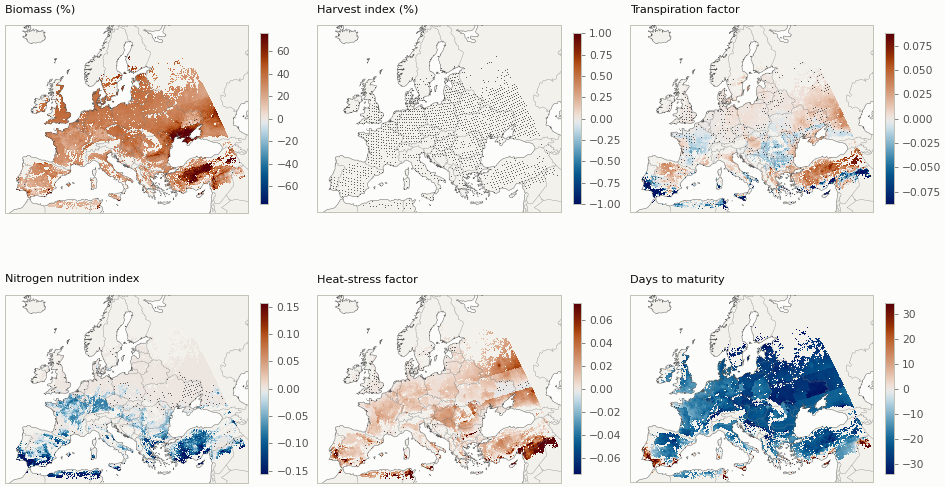

In [3]:
panels = {"Biomass (%)": sc.relative_change(biomass, "ssp370", sc.FAR), "Harvest index (%)": sc.relative_change(y / biomass.where(biomass > 0), "ssp370", sc.FAR),
          "Transpiration factor": sc.absolute_change(tran, "ssp370", sc.FAR), "Nitrogen nutrition index": sc.absolute_change(nni, "ssp370", sc.FAR),
          "Heat-stress factor": sc.absolute_change(heat, "ssp370", sc.FAR), "Days to maturity": sc.absolute_change(maturity, "ssp370", sc.FAR)}
fig, axes = sc.map_axes(2, 3, 3.5, 2.75)
for ax, (name, delta) in zip(axes.ravel(), panels.items()):
    mean = delta.mean("model")
    fig.colorbar(sc.draw_map(ax, mean.values, title=name, hatch=~sc.agreement(delta).values, **sc.diverging(mean)), ax=ax, shrink=0.65)
save(fig, "process_maps", FIGURES)
plt.show()

## 2. The emulator and whether to trust it

Held-out R² in rising order of difficulty. *Leave out model* asks whether the response transfers to a model the emulator has not seen. *Leave out experiment* is the extrapolation test that matters most for CO₂: `hist-aer` removes the only fixed-CO₂ data, and `ssp370` removes all CO₂ above about 475 ppm (`ssp126` peaks at 474).

In [4]:
panel = xp.panel()
panel["period"] = xp.label_periods(panel)
print(f"{len(panel):,} seasons, {panel.SimplaceID.nunique():,} cells, baseline ≥ {xp.MIN_BASE_YIELD} t/ha")
skill = xp.score_splits(panel)
skill.to_csv(TABLES / "emulator_skill.csv", index=False)
display(skill.round(3))

6,827,320 seasons, 4,782 cells, baseline ≥ 1.0 t/ha


,held out,rows,R²,RMSE (%),bias (%)
0,random 20 % of years,1301340,0.698,18.791,0.210
1,leave out model ACCESS-ESM1-5,1713346,0.659,21.416,-0.608
2,leave out model IPSL-CM6A-LR,1715518,0.651,19.324,-0.565
3,leave out model MIROC6,1689454,0.711,18.128,-1.369
4,leave out model MRI-ESM2-0,1709002,0.677,18.803,3.551
5,leave out experiment historical,1207040,0.633,16.785,1.273
6,leave out experiment hist-GHG,1207040,0.637,17.346,-0.344
7,leave out experiment hist-aer,1207040,0.354,18.545,11.209
8,leave out experiment ssp126,1603100,0.623,19.345,-0.397
9,leave out experiment ssp370,1603100,0.341,30.030,-12.532


## 3. Global importance

Final fit on all experiments. SHAP is computed on an equal draw from each model, experiment and period, so the long SSP runs do not dominate. Mean |SHAP| measures how much each part moves a prediction, whether up or down, in % of baseline yield.

Fit R² on the SHAP sample: 0.728


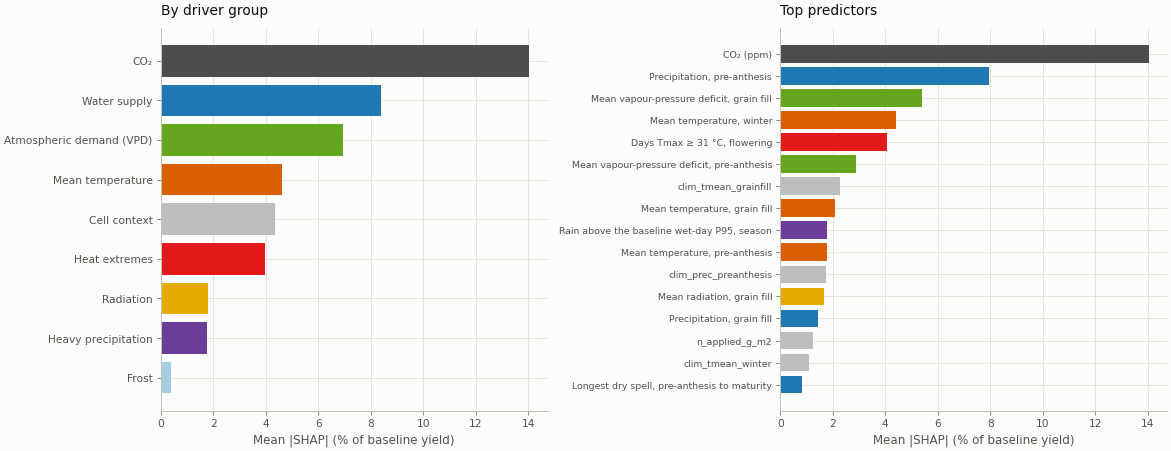

In [5]:
model = xp.fit(panel)
sample = panel.dropna(subset=["period"]).groupby(["model", "experiment", "period"]).sample(25_000, random_state=0).reset_index(drop=True)
shap = xp.contributions(model, sample)
groups = xp.by_group(shap)
print(f"Fit R² on the SHAP sample: {1 - ((sample.anomaly_pct - shap.sum(axis=1)) ** 2).sum() / ((sample.anomaly_pct - sample.anomaly_pct.mean()) ** 2).sum():.3f}")
fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.0), layout="constrained")
imp_g = groups.abs().mean().sort_values()
axes[0].barh([xp.GROUP_LABELS[g] for g in imp_g.index], imp_g.values, color=[GROUP_COLOURS[g] for g in imp_g.index])
axes[0].set(xlabel="Mean |SHAP| (% of baseline yield)", title="By driver group")
imp_f = shap.drop(columns="base").abs().mean().sort_values().tail(16)
axes[1].barh([LABEL(p) for p in imp_f.index], imp_f.values, color=[GROUP_COLOURS[xp.GROUP_OF[p]] for p in imp_f.index])
axes[1].set(xlabel="Mean |SHAP| (% of baseline yield)", title="Top predictors")
axes[1].tick_params(axis="y", labelsize=7.5)
save(fig, "global_importance", FIGURES)
plt.show()
imp_g.rename("mean |SHAP|").to_csv(TABLES / "importance_groups.csv")

### Response curves

The binned mean of each predictor's SHAP against its value. A flat line means the emulator ignores the predictor. For CO₂ the curve is shown per model, with a break where only `ssp370` supplies the data.

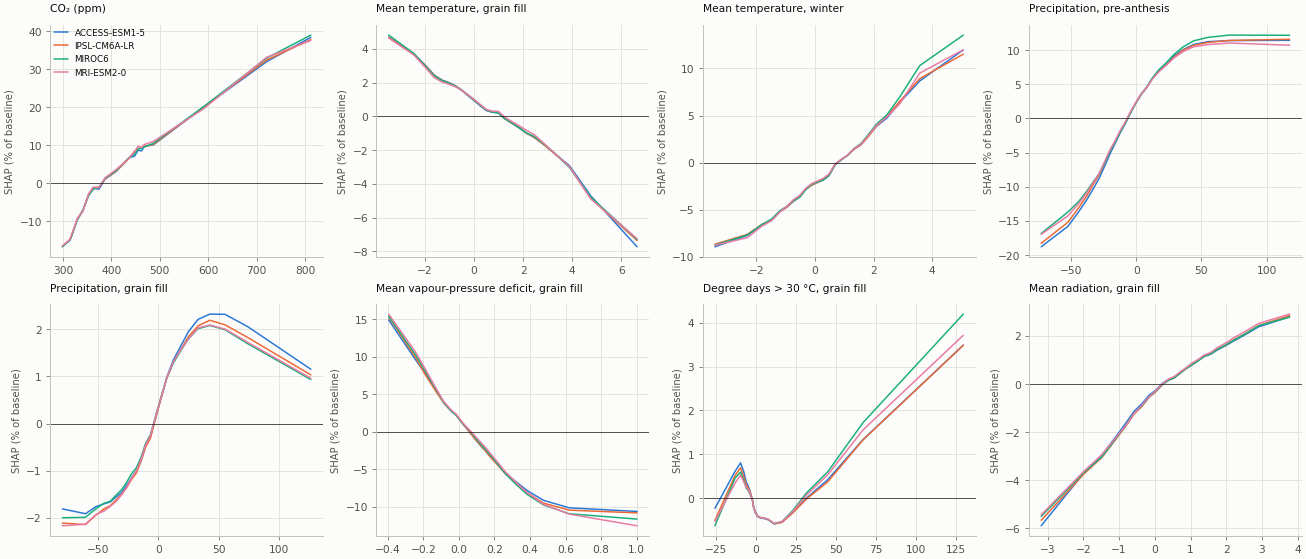

In [6]:
CURVES = [xp.CO2, "d_tmean_grainfill", "d_tmean_winter", "d_prec_preanthesis", "d_prec_grainfill", "d_vpd_grainfill", "d_edd_grainfill", "d_rad_grainfill"]
fig, axes = plt.subplots(2, 4, figsize=(14.5, 6.2), layout="constrained")
for ax, p in zip(axes.ravel(), CURVES):
    edges = np.unique(np.nanquantile(sample[p], np.linspace(0.005, 0.995, 25)))
    for m in sc.MODELS:
        mask = (sample["model"] == m).to_numpy()
        bins = pd.cut(sample.loc[mask, p], edges)
        curve = shap.loc[mask, p].groupby(bins, observed=True).mean()
        ax.plot([b.mid for b in curve.index], curve.values, color=MODEL_COLOURS[m], lw=1.2, label=m)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(LABEL(p), fontsize=8.5)
    ax.set_ylabel("SHAP (% of baseline)", fontsize=8)
axes[0, 0].legend(frameon=False, fontsize=7)
save(fig, "response_curves", FIGURES)
plt.show()

## 4. What drives the change?

The change in mean SHAP from `historical` 1985–2014 to each scenario, per driver. SHAP is additive, so the bars sum to the emulator's change, and the black dot is the **simulated** change on the same rows. A gap between sum and dot is emulator error. Hollow markers are the second rule: what the prediction loses when that group alone is reset to normal.

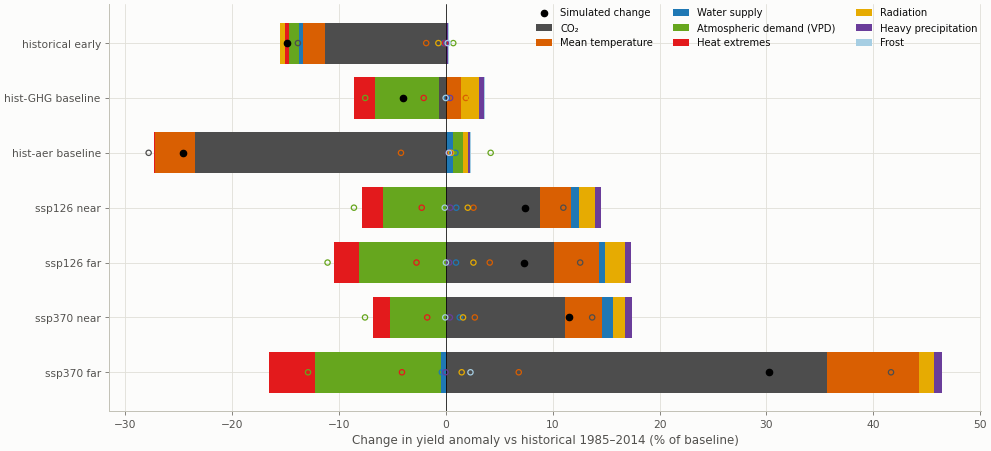

scenario,historical early,hist-GHG baseline,hist-aer baseline,ssp126 near,ssp126 far,ssp370 near,ssp370 far
co2,-11.3,-0.7,-23.5,8.8,10.1,11.2,35.7
temperature,-2.0,1.4,-3.8,2.9,4.2,3.5,8.6
water,-0.4,0.0,0.6,0.8,0.5,1.0,-0.4
vpd,-0.9,-6.0,1.0,-5.9,-8.1,-5.2,-11.8
heat,-0.4,-1.9,-0.1,-1.9,-2.4,-1.6,-4.3
radiation,-0.5,1.6,0.4,1.5,1.9,1.1,1.4
wet,0.2,0.5,0.2,0.6,0.6,0.6,0.7
frost,0.1,0.0,0.2,-0.0,-0.0,-0.0,-0.0
sum,-15.3,-4.9,-24.9,6.6,6.8,10.6,29.9
emulated,-15.5,-5.0,-24.8,6.7,6.8,10.8,29.8


Second rule, group reset to normal:


scenario,historical early,hist-GHG baseline,hist-aer baseline,ssp126 near,ssp126 far,ssp370 near,ssp370 far
co2,-13.8,0.1,-27.8,11.0,12.6,13.7,41.7
temperature,-1.8,1.9,-4.2,2.6,4.1,2.7,6.8
water,-0.2,0.1,0.9,1.0,1.0,1.3,-0.4
vpd,0.7,-7.5,4.2,-8.6,-11.1,-7.6,-12.9
heat,-0.1,-2.1,0.4,-2.3,-2.7,-1.7,-4.1
radiation,-0.7,2.3,0.5,2.1,2.6,1.6,1.5
wet,0.0,0.4,0.3,0.4,0.3,0.4,-0.0
frost,0.2,-0.0,0.3,-0.1,0.0,-0.1,2.3


In [7]:
def period_means(frame, values):
    return values.groupby([frame["model"].to_numpy(), frame["experiment"].to_numpy(), frame["period"].to_numpy()]).mean()

mean_shap = period_means(sample, groups[DRIVERS])
sim = period_means(sample, sample["anomaly_pct"])
pred = period_means(sample, shap.sum(axis=1))
base_key = ("historical", "baseline")
rows, cf_rows = [], []
for e, name in SCEN:
    for m in sc.MODELS:
        delta = mean_shap.loc[(m, e, name)] - mean_shap.loc[(m, *base_key)]
        rows.append({"model": m, "scenario": f"{e} {name}", **delta.to_dict(), "sum": float(delta.sum()),
                     "emulated": float(pred.loc[(m, e, name)] - pred.loc[(m, *base_key)]), "simulated": float(sim.loc[(m, e, name)] - sim.loc[(m, *base_key)])})
        rows_now = sample[(sample["model"] == m) & (sample["experiment"] == e) & (sample["period"] == name)]
        rows_base = sample[(sample["model"] == m) & (sample["experiment"] == base_key[0]) & (sample["period"] == base_key[1])]
        cf_rows.append({"model": m, "scenario": f"{e} {name}", **{g: float(xp.counterfactual(model, rows_now, g).mean() - xp.counterfactual(model, rows_base, g).mean()) for g in DRIVERS}})
attribution, counter = pd.DataFrame(rows), pd.DataFrame(cf_rows)
attribution.to_csv(TABLES / "shap_attribution.csv", index=False)
counter.to_csv(TABLES / "counterfactual_attribution.csv", index=False)

means, cf_means = attribution.groupby("scenario", sort=False).mean(numeric_only=True), counter.groupby("scenario", sort=False).mean(numeric_only=True)
fig, ax = plt.subplots(figsize=(11.0, 5.0), layout="constrained")
pos, neg = np.zeros(len(means)), np.zeros(len(means))
yy = np.arange(len(means))
for g in DRIVERS:
    v = means[g].to_numpy()
    ax.barh(yy, v, left=np.where(v >= 0, pos, neg), color=GROUP_COLOURS[g], label=xp.GROUP_LABELS[g], height=0.75)
    pos, neg = pos + np.clip(v, 0, None), neg + np.clip(v, None, 0)
    ax.scatter(cf_means[g], yy, s=18, facecolors="none", edgecolors=GROUP_COLOURS[g], zorder=5, linewidths=1.0)
ax.scatter(means["simulated"], yy, color="k", s=26, zorder=6, label="Simulated change")
ax.axvline(0, color="k", lw=0.6)
ax.set_yticks(yy, means.index)
ax.invert_yaxis()
ax.set_xlabel("Change in yield anomaly vs historical 1985–2014 (% of baseline)")
ax.legend(frameon=False, ncol=3, fontsize=8)
save(fig, "attribution", FIGURES)
plt.show()
display(means.round(1).T)
print("Second rule, group reset to normal:")
display(cf_means.round(1).T)

### Checking the CO₂ share against the crop file

Crop parameter `COTB` multiplies radiation-use efficiency by a prescribed function of CO₂, so its effect on biomass can be computed with no statistics. If growth scaled directly with RUE, the table's mean over each period would predict the CO₂ share. The last column divides that factor out of the simulated change and leaves an estimate of everything else: climate, plus CO₂'s other route through transpiration. The same `COTB` table is in all regional crops (the code raises an error otherwise).

In [8]:
ppm, rue = xp.cotb_table()
print("COTB:", dict(zip(ppm, rue)))
co2 = sc.co2_series()
factor = lambda e, s: float(np.interp(co2[e].loc[s[0]:s[1]].dropna().to_numpy(), ppm, rue).mean())
reference_factor = factor("historical", sc.BASELINE)
check = pd.DataFrame([{"scenario": f"{e} {name}", "mean CO₂ (ppm)": float(co2[e].loc[SPANS[name][0]:SPANS[name][1]].mean()),
                       "COTB alone (%)": 100 * (factor(e, SPANS[name]) / reference_factor - 1),
                       "SHAP CO₂ (%)": means.loc[f"{e} {name}", "co2"], "reset-to-normal CO₂ (%)": cf_means.loc[f"{e} {name}", "co2"],
                       "simulated (%)": means.loc[f"{e} {name}", "simulated"],
                       "simulated without COTB (%)": 100 * ((1 + means.loc[f"{e} {name}", "simulated"] / 100) * reference_factor / factor(e, SPANS[name]) - 1)} for e, name in SCEN]).set_index("scenario")
check.to_csv(TABLES / "co2_table_check.csv")
display(check.round(1))

COTB: {np.float64(40.0): np.float64(0.0), np.float64(360.0): np.float64(1.0), np.float64(720.0): np.float64(1.350000023841858), np.float64(1000.0): np.float64(1.5), np.float64(2000.0): np.float64(1.5)}


,mean CO₂ (ppm),COTB alone (%),SHAP CO₂ (%),reset-to-normal CO₂ (%),simulated (%),simulated without COTB (%)
scenario,,,,,,
historical early,322.4,-12.1,-11.3,-13.8,-14.9,-3.1
hist-GHG baseline,369.7,0.0,-0.7,0.1,-4.0,-4.0
hist-aer baseline,284.3,-24.0,-23.5,-27.8,-24.6,-0.9
ssp126 near,448.0,8.1,8.8,11.0,7.4,-0.7
ssp126 far,461.0,9.4,10.1,12.6,7.3,-1.9
ssp370 near,475.7,10.8,11.2,13.7,11.5,0.6
ssp370 far,757.3,36.0,35.7,41.7,30.3,-4.2


Per model, for `ssp370` far: does the same driver dominate in every model?

In [9]:
display(attribution[attribution["scenario"].isin(["ssp126 far", "ssp370 far"])].set_index(["scenario", "model"]).round(1).T)

scenario       ssp126 far                                   ssp370 far  \
model       ACCESS-ESM1-5 IPSL-CM6A-LR MIROC6 MRI-ESM2-0 ACCESS-ESM1-5   
co2                   9.5         10.4    9.9       10.6          35.6   
temperature           5.3          5.7    4.1        1.8           8.0   
water                -0.1          2.3   -0.3        0.1           0.1   
vpd                 -12.3         -7.3   -8.7       -4.3         -13.9   
heat                 -3.9         -1.9   -2.6       -1.0          -5.5   
radiation             2.2          1.4    1.6        2.5           1.8   
wet                   0.8          0.3    0.4        0.8           0.8   
frost                -0.0         -0.0   -0.0        0.0          -0.1   
sum                   1.5         10.9    4.5       10.4          26.7   
emulated              1.3         10.5    5.0       10.5          27.2   
simulated             3.1         10.2    6.0       10.0          27.8   

scenario                                    
model       IPSL-CM6A-LR MIROC6 MRI-ESM2-0  
co2                 35.4   36.2       35.5  
temperature          9.2    9.5        7.6  
water               -1.1   -1.2        0.4  
vpd                -16.5   -9.9       -6.9  
heat                -3.9   -3.5       -4.1  
radiation            1.2    1.2        1.5  
wet                  0.4    0.8        0.9  
frost                0.0    0.1       -0.0  
sum                 24.8   33.1       34.9  
emulated            23.6   33.8       34.5  
simulated           22.9   36.3       34.1

### By region

The same attribution by AR6 region, for the far-future scenarios.

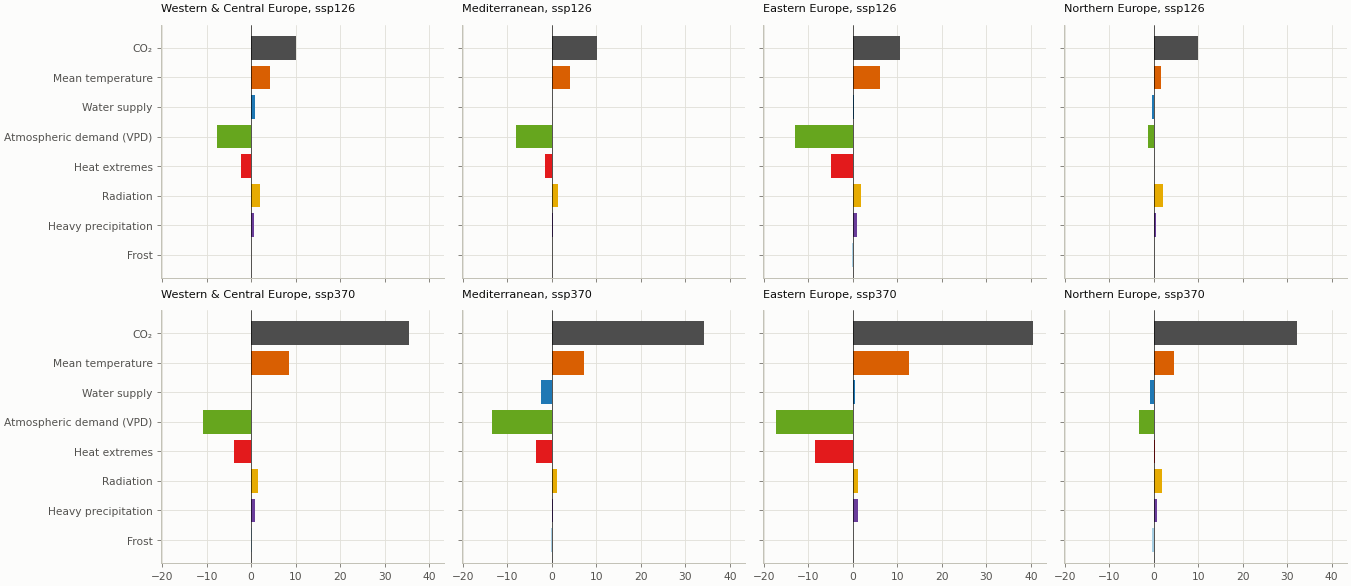

experiment       ssp126                       ssp370                     
region              WCE    MED    EEU    NEU     WCE    MED    EEU    NEU
co2                10.0   10.1   10.7    9.8    35.5   34.1   40.5   32.2
temperature         4.2    4.0    6.1    1.7     8.6    7.3   12.7    4.5
water               0.8   -0.0    0.3   -0.5    -0.0   -2.6    0.5   -0.9
vpd                -7.7   -8.2  -13.1   -1.2   -10.8  -13.5  -17.4   -3.3
heat               -2.2   -1.5   -4.8    0.0    -3.9   -3.6   -8.5    0.3
radiation           2.1    1.3    1.8    2.2     1.6    1.0    1.1    1.8
wet                 0.6    0.3    0.9    0.4     0.8    0.2    1.2    0.8
frost              -0.0    0.1   -0.2   -0.0     0.1   -0.2   -0.1   -0.4
cells in sample  3001.0  791.0  554.0  252.0  3001.0  791.0  554.0  252.0

In [10]:
regions = {"WCE": "Western & Central Europe", "MED": "Mediterranean", "EEU": "Eastern Europe", "NEU": "Northern Europe"}
fig, axes = plt.subplots(2, 4, figsize=(15.0, 6.5), sharey=True, sharex=True, layout="constrained")
rows = []
for r_i, e in enumerate(sc.FUTURE):
    for ax, (r, label) in zip(axes[r_i], regions.items()):
        mask = (sample["ar6"] == r).to_numpy()
        now = groups.loc[mask & (sample["experiment"] == e).to_numpy() & (sample["period"] == "far").to_numpy(), DRIVERS].mean()
        ref = groups.loc[mask & (sample["experiment"] == "historical").to_numpy() & (sample["period"] == "baseline").to_numpy(), DRIVERS].mean()
        delta = now - ref
        rows.append({"experiment": e, "region": r, **delta.to_dict(), "cells in sample": int(sample.loc[mask, "SimplaceID"].nunique())})
        ax.barh([xp.GROUP_LABELS[g] for g in DRIVERS], delta.values, color=[GROUP_COLOURS[g] for g in DRIVERS])
        ax.axvline(0, color="k", lw=0.5)
        ax.set_title(f"{label}, {e}", fontsize=9)
axes[0, 0].invert_yaxis()
pd.DataFrame(rows).to_csv(TABLES / "shap_attribution_regions.csv", index=False)
save(fig, "attribution_regions", FIGURES)
plt.show()
display(pd.DataFrame(rows).set_index(["experiment", "region"]).round(1).T)

## 5. Where each driver dominates

The strongest negative climate driver (CO₂ excluded) per 1° box in `ssp370` 2071–2100 against the baseline, using the sampled cells. Boxes with fewer than 3 sampled cells are blank. A box is shaded by the size of that driver's change, so a pale box has a weak signal.

,vpd,water,temperature,heat,frost
ssp126,429,10,1,1,1


,vpd,water,heat
ssp370,438,3,1


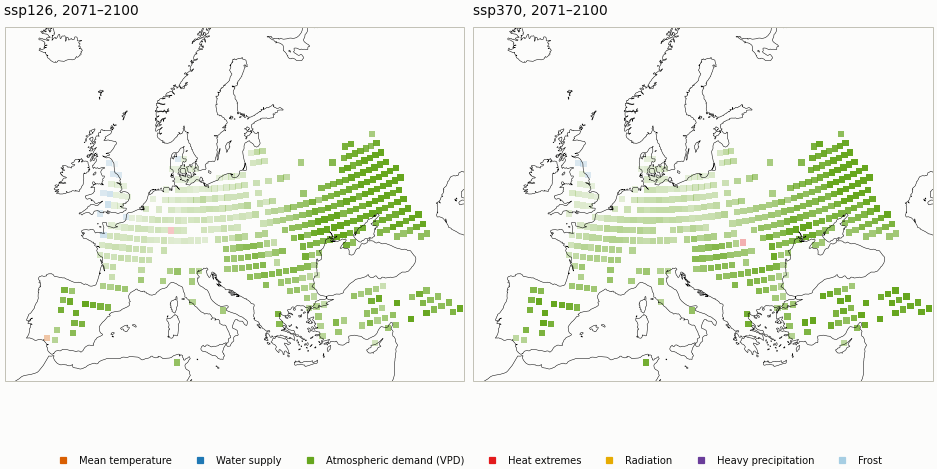

In [11]:
import cartopy.crs as ccrs
from matplotlib.lines import Line2D

climate = [g for g in DRIVERS if g != "co2"]
box = sample.assign(lat_box=np.floor(sample["lat"]) + 0.5, lon_box=np.floor(sample["lon"]) + 0.5)
fig, axes = sc.map_axes(1, 2, 5.2, 5.0)
for ax, e in zip(axes[0], sc.FUTURE):
    now = groups[climate][(box["experiment"] == e) & (box["period"] == "far")].join(box[["lat_box", "lon_box", "SimplaceID"]])
    ref = groups[climate][(box["experiment"] == "historical") & (box["period"] == "baseline")].join(box[["lat_box", "lon_box", "SimplaceID"]])
    enough = now.groupby(["lat_box", "lon_box"])["SimplaceID"].nunique() >= 3
    delta = (now.groupby(["lat_box", "lon_box"])[climate].mean() - ref.groupby(["lat_box", "lon_box"])[climate].mean())[enough].dropna()
    driver, size = delta.idxmin(axis=1), delta.min(axis=1)
    alpha = np.clip(-size / float(np.quantile(-size, 0.9)), 0.15, 1.0)
    ax.set_extent(sc.MAP_EXTENT, crs=ccrs.PlateCarree())
    ax.coastlines(lw=0.4)
    ax.scatter(delta.index.get_level_values("lon_box"), delta.index.get_level_values("lat_box"), c=driver.map(GROUP_COLOURS), alpha=alpha, s=26, marker="s", transform=ccrs.PlateCarree(), linewidths=0)
    ax.set_title(f"{e}, {SPAN(sc.FAR)}")
    display(driver.value_counts().rename(e).to_frame().T)
fig.legend(handles=[Line2D([], [], marker="s", ls="", color=GROUP_COLOURS[g], label=xp.GROUP_LABELS[g]) for g in climate], loc="outside lower center", ncol=len(climate), frameon=False, fontsize=8)
save(fig, "dominant_driver", FIGURES)
plt.show()

## 6. What makes a season extreme?

Seasons below the cell's 1-in-10 level (`historical` 1985–2014, per model and cell). Each bar is the mean SHAP in those seasons minus the mean SHAP over all seasons of the same scenario and period, so it isolates what separates a bad season from a normal one in that climate. CO₂ barely varies within a period, so it should barely appear.

seasons  probability (%)  co2  temperature  water  \
scenario            region                                                      
historical baseline All       10035             10.0 -1.8         -1.0  -10.8   
                    WCE        6409             10.0 -1.7         -0.7  -10.2   
                    MED        1582             10.0 -1.8         -1.2  -14.1   
                    EEU        1148              9.9 -2.4         -1.8  -13.4   
                    NEU         559             10.6 -1.5         -1.4   -2.8   
ssp126 far          All        8938              8.9 -2.6         -1.9  -13.3   
                    WCE        5315              8.3 -2.4         -2.0  -12.9   
                    MED        1516              9.6 -2.2         -2.2  -13.7   
                    EEU        1511             13.0 -3.7         -2.3  -15.1   
                    NEU         129              2.4 -1.3         -1.0  -11.8   
ssp370 far          All        4787              4.8 -5.4         -4.4  -10.3   
                    WCE        2471              3.9 -2.8         -1.9  -10.4   
                    MED        1257              8.0 -7.6         -6.6  -10.1   
                    EEU         526              4.5 -7.2         -3.8  -11.1   
                    NEU           7              0.1  0.4         -4.0  -17.2   

                             vpd  heat  radiation  wet  frost  
scenario            region                                     
historical baseline All     -7.6  -2.9        0.5 -1.1   -0.1  
                    WCE     -7.2  -2.5        0.5 -1.0   -0.1  
                    MED     -6.8  -1.4        0.8 -1.3    0.0  
                    EEU    -14.0  -7.8        1.2 -1.6   -0.2  
                    NEU     -0.4  -0.0       -1.2 -0.3    0.0  
ssp126 far          All     -9.2  -5.3        0.1 -1.0   -0.1  
                    WCE     -8.9  -5.0        0.1 -1.0   -0.1  
                    MED     -6.1  -2.5       -0.0 -0.9   -0.1  
                    EEU    -11.3  -8.2        0.3 -1.3   -0.1  
                    NEU     -5.0  -0.5        0.8 -0.9    0.0  
ssp370 far          All    -10.3  -5.5       -0.2 -1.1   -0.9  
                    WCE    -10.5  -6.0       -0.3 -1.1   -0.4  
                    MED     -5.8  -2.1       -0.1 -1.0   -0.9  
                    EEU    -13.8  -8.1        0.4 -1.0   -0.5  
                    NEU     -7.7  -6.6        1.2 -1.9    0.2

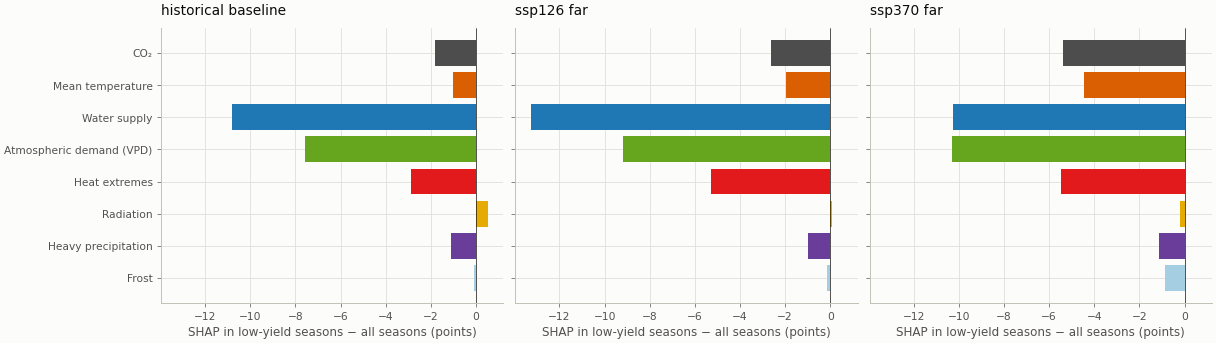

In [12]:
base_rows = panel[(panel["experiment"] == "historical") & panel["year"].between(*sc.BASELINE)]
limits = base_rows.groupby(["model", "SimplaceID"])["yield_t_ha"].quantile(0.10).rename("limit")
flagged = sample.join(limits, on=["model", "SimplaceID"])
low = (flagged["yield_t_ha"] < flagged["limit"]).to_numpy()
rows = []
for e, name in [("historical", "baseline"), ("ssp126", "far"), ("ssp370", "far")]:
    block = ((sample["experiment"] == e) & (sample["period"] == name)).to_numpy()
    for r in (None, "WCE", "MED", "EEU", "NEU"):
        where = block if r is None else block & (sample["ar6"] == r).to_numpy()
        delta = groups.loc[where & low, DRIVERS].mean() - groups.loc[where, DRIVERS].mean()
        rows.append({"scenario": f"{e} {name}", "region": r or "All", "seasons": int((where & low).sum()), "probability (%)": 100 * float(low[where].mean()), **delta.to_dict()})
anatomy = pd.DataFrame(rows)
anatomy.to_csv(TABLES / "extreme_anatomy.csv", index=False)
display(anatomy.set_index(["scenario", "region"]).round(1))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8), sharex=True, sharey=True, layout="constrained")
for ax, (name, block) in zip(axes, anatomy[anatomy["region"] == "All"].groupby("scenario", sort=False)):
    values = block[DRIVERS].iloc[0]
    ax.barh([xp.GROUP_LABELS[g] for g in DRIVERS], values.to_numpy(), color=[GROUP_COLOURS[g] for g in DRIVERS])
    ax.axvline(0, color="k", lw=0.5)
    ax.set(title=name, xlabel="SHAP in low-yield seasons − all seasons (points)")
axes[0].invert_yaxis()
save(fig, "extreme_anatomy", FIGURES)
plt.show()

## 7. Limits of this attribution

* **Correlated drivers.** Mean temperature, VPD and heat extremes rise together, so their individual bars are less firm than their sum. Compare the group totals rather than ranking within the warm groups.
* **Fixed windows.** Indices use each cell's baseline phenology. In a warmer season the crop flowers earlier, so late-window heat may fall after real maturity. Windows that follow the crop would hide its response.
* **Emulated CO₂.** The CO₂ response above ~475 ppm is informed only by `ssp370`, and the leave-out row in §2 shows how far it can be trusted.
* **A decisive check.** Rerunning torchcrop on `ssp370` weather with CO₂ held at about 400 ppm, and the reverse, would give the CO₂ effect directly with no statistical split. It costs one run, about 2 h for each model and experiment.